In [1]:
import numpy as np
import torch as tc
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from datetime import datetime

In [2]:
path = '/Users/eta/.cache/kagglehub/competitions/spaceship-titanic'
dataset = pd.read_csv(path + '/train.csv')

---

In [3]:
dataset_df = dataset.copy()

In [4]:
# dataset_df[["Deck", "Cabin_num", "Side"]] = dataset_df["Cabin"].str.split("/", expand=True)

In [5]:
# dorp the meanless columns
dataset_df = dataset_df.drop(['PassengerId', 'Cabin', 'Name'], axis=1)

# for Age: replace the nan with the mean value.
dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

# for bill: replace the nan with zero value. 
for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
    dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)
    
# for category: using the one-hot encoding.
for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
#     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
    dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')

In [7]:
# one-hot encoding:
for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
#     print(len(dataset_df[name].unique()), dataset_df[name].unique())
    for key in dataset_df[name].unique():
        dataset_df[f'{name}_{key}'] = 0
        dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1
        
    dataset_df.drop(columns=[name], inplace=True)

In [9]:
# split the dataset
dataset_x = dataset_df.drop(columns=['Transported'])
dataset_y = dataset_df['Transported']

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
    stratify=dataset_y
)

In [3]:
def getData(dataset_df: pd.DataFrame, istest=False):
    # dorp the meanless columns
    dataset_df = dataset_df.drop(['PassengerId', 'Cabin', 'Name'], axis=1)

    # for Age: replace the nan with the mean value.
    dataset_df['Age'] = dataset_df['Age'].fillna(dataset_df['Age'].mean().round())

    # for bill: replace the nan with zero value. 
    for name in ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']:
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna(0)

    # for category: using the one-hot encoding.
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
    #     print(len(dataset_df[f'{name}'].unique()), dataset_df[f'{name}'].unique())
        dataset_df[f'{name}'] = dataset_df[f'{name}'].fillna('Missing')
        
    # one-hot encoding:
    for name in ['HomePlanet', 'Destination', 'CryoSleep', 'VIP']:
    #     print(len(dataset_df[name].unique()), dataset_df[name].unique())
        for key in dataset_df[name].unique():
            dataset_df[f'{name}_{key}'] = 0
            dataset_df.loc[dataset_df[name] == key, f'{name}_{key}'] = 1

        dataset_df.drop(columns=[name], inplace=True)
    
    if istest:
        return dataset_df
    else:
        dataset_x = dataset_df.drop(columns=['Transported'])
        dataset_y = dataset_df['Transported']

        return dataset_x, dataset_y

### logistic regression

In [21]:
dataset_x, dataset_y = getData(dataset)

x_train_df, x_val_df, y_train_df, y_val_df = train_test_split(
    dataset_x,
    dataset_y,
    test_size=0.2,
    random_state=42,
#     stratify=dataset_y
)

In [22]:
x_train = tc.tensor(x_train_df.to_numpy())
y_train = tc.tensor(y_train_df.to_numpy(), dtype=tc.float64).reshape([-1, 1])

x_val = tc.tensor(x_val_df.to_numpy())
y_val = tc.tensor(y_val_df.to_numpy(), dtype=tc.float64).reshape([-1, 1])

In [23]:
input_dim = x_train.shape[1]
model = tc.nn.Linear(input_dim, 1, dtype=tc.float64)
loss = tc.nn.BCEWithLogitsLoss()
# optimizer = tc.optim.SGD(model.parameters(), lr=lr)
optimizer = tc.optim.Adam(model.parameters(), lr=1e-4)

In [24]:
train_loss_list = []
val_loss_list = []
train_acc_list = []
val_acc_list = []

epoch_num = 6000
lr_list = [1e-2, 1e-3, 1e-4, 1e-5, 1e-8, 1e-9]

for epoch in range(epoch_num):
    
    if epoch <= 1000:
        lr = lr_list[0]
    elif epoch <= 2000 and epoch > 1000:
        lr = lr_list[1]
    elif epoch <= 3000 and epoch > 2000:
        lr = lr_list[2]
    elif epoch <= 4000 and epoch > 3000:
        lr = lr_list[3]
    elif epoch <= 5000 and epoch > 4000:
        lr = lr_list[4]
    elif epoch <= 6000 and epoch > 5000:
        lr = lr_list[5]
        
    optimizer.param_groups[0]['lr'] = lr
        
    # clear the grad
    optimizer.zero_grad()
    
    # forward
    train_logits = model(x_train)
    # calculate loss
    train_loss = loss(train_logits, y_train)
    # backword & calculate grad
    train_loss.backward()
    # update parameter model.wight
    optimizer.step()
    
    with tc.no_grad():
        
        val_logits = model(x_val)
        val_loss = loss(val_logits, y_val)
        
        train_acc = tc.mean(((train_logits > 0).float() == y_train).float())
        val_acc = tc.mean(((val_logits > 0).float() == y_val).float())
        
    train_loss_list.append(train_loss.item())
    val_loss_list.append(val_loss.item())
    
    train_acc_list.append(train_acc.item())
    val_acc_list.append(val_acc.item())
    
# results = (tc.sigmoid(model(x_val)) > 0).float()
# accuracy = tc.mean((results == y_val).float())
# print(accuracy)

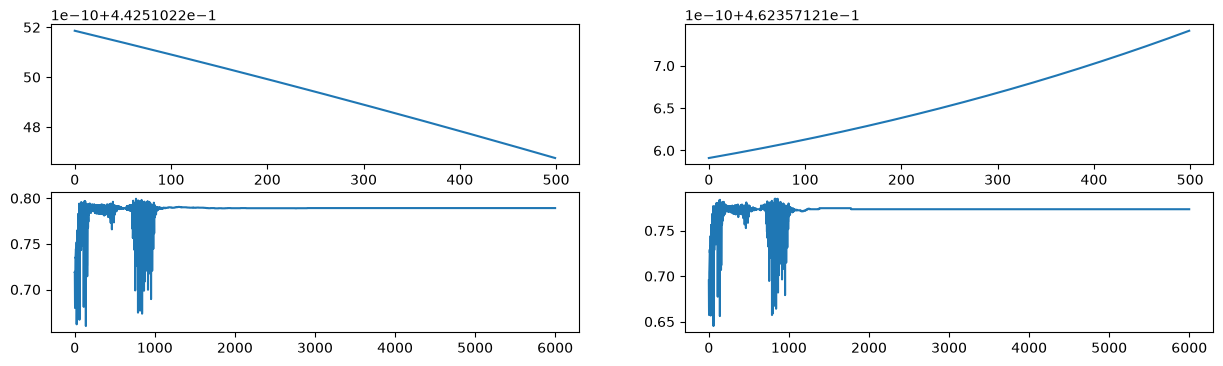

In [42]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(15, 4))
ax[0][0].plot(train_loss_list[-500:])
ax[0][1].plot(val_loss_list[-500:])

ax[1][0].plot(train_acc_list)
ax[1][1].plot(val_acc_list)

In [43]:
print(train_acc, val_acc)

tensor(0.7892) tensor(0.7734)


In [44]:
test = pd.read_csv(path + '/test.csv')
sample = pd.read_csv(path + '/sample_submission.csv')

test_df = getData(test, istest=True)
test_df = test_df.reindex(
    columns=dataset_x.columns,
    fill_value=0
)

test_x = tc.tensor(test_df.to_numpy())

test_pred = model(test_x) > 0

submit = sample.copy()
submit['Transported'] = test_pred

In [45]:
submit

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,False
...,...,...
4272,9266_02,True
4273,9269_01,False
4274,9271_01,True
4275,9273_01,True


In [46]:
submit.to_csv(f'./data/submit_{datetime.now().isoformat()}.csv', index=False)
submit.to_csv(f'./submit.csv', index=False)

In [47]:
ls

data/                                   titanic_alpha_logic_registration.ipynb
submit.csv                              titanic_dataset.ipynb


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model_lr = LogisticRegression(max_iter=1000)

model_lr.fit(X_train, y_train)

y_pred = model_lr.predict(X_val)

acc = accuracy_score(y_val, y_pred)

print("Validation accuracy:", acc)

Validation accuracy: 0.7832087406555491


/Users/eta/anaconda3/envs/kaggle/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [26]:
from sklearn.metrics import log_loss

train_prob = model_lr.predict_proba(X_train)
train_loss = log_loss(y_train, train_prob)

print("Train loss:", train_loss)

Train loss: 0.44619579202053483


In [34]:
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, accuracy_score
import numpy as np

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

model = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    learning_rate="constant",
    eta0=1e-4,
    random_state=42,
    average=True
)

classes = np.unique(y_train)

for epoch in range(20000):

    if epoch == 0:
        model.partial_fit(
            X_train,
            y_train,
            classes=classes
        )
    else:
        model.partial_fit(
            X_train,
            y_train
        )

    if epoch % 500 == 0:

        train_prob = model.predict_proba(X_train)
        val_prob = model.predict_proba(X_val)

        train_loss = log_loss(y_train, train_prob)
        val_loss = log_loss(y_val, val_prob)

        train_acc = accuracy_score(
            y_train,
            model.predict(X_train)
        )

        val_acc = accuracy_score(
            y_val,
            model.predict(X_val)
        )

        print(
            f"Epoch {epoch:3d} | "
            f"train loss = {train_loss:.4f} | "
            f"val loss = {val_loss:.4f} | "
            f"train acc = {train_acc:.4f} | "
            f"val acc = {val_acc:.4f}"
        )

Epoch   0 | train loss = 4.3781 | val loss = 4.3209 | train acc = 0.7820 | val acc = 0.7907
Epoch 500 | train loss = 4.3496 | val loss = 4.3275 | train acc = 0.7834 | val acc = 0.7901
Epoch 1000 | train loss = 4.3464 | val loss = 4.3241 | train acc = 0.7837 | val acc = 0.7895
Epoch 1500 | train loss = 4.3465 | val loss = 4.3247 | train acc = 0.7840 | val acc = 0.7895
Epoch 2000 | train loss = 4.3476 | val loss = 4.3259 | train acc = 0.7843 | val acc = 0.7895
Epoch 2500 | train loss = 4.3483 | val loss = 4.3267 | train acc = 0.7840 | val acc = 0.7895
Epoch 3000 | train loss = 4.3496 | val loss = 4.3281 | train acc = 0.7842 | val acc = 0.7895
Epoch 3500 | train loss = 4.3504 | val loss = 4.3291 | train acc = 0.7842 | val acc = 0.7895
Epoch 4000 | train loss = 4.3514 | val loss = 4.3298 | train acc = 0.7842 | val acc = 0.7895
Epoch 4500 | train loss = 4.3522 | val loss = 4.3305 | train acc = 0.7842 | val acc = 0.7895
Epoch 5000 | train loss = 4.3530 | val loss = 4.3315 | train acc = 0.784

KeyboardInterrupt: 

In [ ]:
Chu